In [4]:
# ============================================
# STEP 2: IMPORT LIBRARIES AND CONFIGURATION
# ============================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

from IPython.display import display

# Project directories
# Automatically locate the project root
current_dir = Path.cwd()

if (current_dir / "data" / "processed").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data" / "processed").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Could not locate Traffic_Sign_Recognition project root."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"

CONFUSION_DIR = OUTPUTS_DIR / "confusion_matrices"
ROBUSTNESS_DIR = OUTPUTS_DIR / "robustness"

# Create output directories
CONFUSION_DIR.mkdir(parents=True, exist_ok=True)
ROBUSTNESS_DIR.mkdir(parents=True, exist_ok=True)

# Image configuration
IMG_HEIGHT = 64
IMG_WIDTH = 64
IMG_CHANNELS = 3
NUM_CLASSES = 43
BATCH_SIZE = 64

print("TensorFlow version:", tf.__version__)
print("Project root:", PROJECT_ROOT)
print("Models directory:", MODELS_DIR)
print("Confusion matrices directory:", CONFUSION_DIR)
print("Robustness directory:", ROBUSTNESS_DIR)

TensorFlow version: 2.21.0
Project root: c:\Projects\Traffic_Sign_Recognition
Models directory: c:\Projects\Traffic_Sign_Recognition\models
Confusion matrices directory: c:\Projects\Traffic_Sign_Recognition\outputs\confusion_matrices
Robustness directory: c:\Projects\Traffic_Sign_Recognition\outputs\robustness


In [5]:
# ============================================
# STEP 3: LOAD OFFICIAL TEST METADATA
# ============================================

test_df = pd.read_csv(
    PROCESSED_DIR / "test_metadata.csv"
)

print("Test dataset shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

print("\nClass distribution:")
print(test_df["ClassId"].value_counts().sort_index())

print("\nNumber of unique classes:",
      test_df["ClassId"].nunique())

print("\nTotal test images:", len(test_df))

Test dataset shape: (12630, 9)

Columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'ImagePath']

Class distribution:
ClassId
0      60
1     720
2     750
3     450
4     660
5     630
6     150
7     450
8     450
9     480
10    660
11    420
12    690
13    720
14    270
15    210
16    150
17    360
18    390
19     60
20     90
21     90
22    120
23    150
24     90
25    480
26    180
27     60
28    150
29     90
30    150
31    270
32     60
33    210
34    120
35    390
36    120
37     60
38    690
39     90
40     90
41     60
42     90
Name: count, dtype: int64

Number of unique classes: 43

Total test images: 12630


In [6]:
# Load the three trained models

baseline_model = tf.keras.models.load_model(
    MODELS_DIR / "cnn_baseline.keras"
)

efficientnet_model = tf.keras.models.load_model(
    MODELS_DIR / "efficientnet_b0.keras"
)

heavy_aug_model = tf.keras.models.load_model(
    MODELS_DIR / "cnn_heavy_augmentation.keras"
)

print("All three models loaded successfully!")

print("\nModel input and output shapes:")
print("Baseline CNN:", baseline_model.input_shape, "->", baseline_model.output_shape)
print("EfficientNetB0:", efficientnet_model.input_shape, "->", efficientnet_model.output_shape)
print("Heavy Augmentation CNN:", heavy_aug_model.input_shape, "->", heavy_aug_model.output_shape)

All three models loaded successfully!

Model input and output shapes:
Baseline CNN: (None, 64, 64, 3) -> (None, 43)
EfficientNetB0: (None, 64, 64, 3) -> (None, 43)
Heavy Augmentation CNN: (None, 64, 64, 3) -> (None, 43)


In [7]:
# Image loading and preprocessing function

def preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [8]:
# Create clean test dataset

test_paths = test_df["ImagePath"].astype(str).values
test_labels = test_df["ClassId"].astype("int32").values

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_dataset = test_dataset.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(BATCH_SIZE)

test_dataset = test_dataset.prefetch(
    tf.data.AUTOTUNE
)

print("Clean test dataset created successfully!")

Clean test dataset created successfully!


In [9]:
# Verify one batch

for images, labels in test_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("Label data type:", labels.dtype)

Image batch shape: (64, 64, 64, 3)
Label batch shape: (64,)
Minimum pixel value: 0.0026448567
Maximum pixel value: 1.0
Label data type: <dtype: 'int32'>


In [10]:
# Evaluation function

def evaluate_model(model, dataset, model_name):

    y_true = []
    y_pred = []

    predictions = model.predict(dataset, verbose=1)

    # Extract true labels from the dataset
    for _, labels in dataset:
        y_true.extend(labels.numpy())

    # Convert probabilities into predicted class IDs
    y_pred = np.argmax(predictions, axis=1)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    results = {
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-score": f1
    }

    return results, np.array(y_true), y_pred

In [11]:
# Evaluate all three models on clean test data

baseline_results, y_true, baseline_predictions = evaluate_model(
    baseline_model,
    test_dataset,
    "Baseline CNN"
)

efficientnet_results, _, efficientnet_predictions = evaluate_model(
    efficientnet_model,
    test_dataset,
    "EfficientNetB0"
)

heavy_aug_results, _, heavy_aug_predictions = evaluate_model(
    heavy_aug_model,
    test_dataset,
    "CNN with Heavy Augmentation"
)

print("Clean test evaluation completed!")

198/198 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 15s 71ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step
Clean test evaluation completed!


In [12]:
# Create model comparison table

clean_results_df = pd.DataFrame([
    baseline_results,
    efficientnet_results,
    heavy_aug_results
])

clean_results_df = clean_results_df.set_index("Model")

display(
    clean_results_df.style.format("{:.4f}")
)

,Accuracy,Macro Precision,Macro Recall,Macro F1-score
Model,,,,
Baseline CNN,0.9918,0.9874,0.9863,0.9865
EfficientNetB0,0.7539,0.6879,0.6700,0.6724
CNN with Heavy Augmentation,0.9912,0.9871,0.9862,0.9864


In [13]:
# Generate per-class classification reports

class_names = [str(i) for i in range(NUM_CLASSES)]

baseline_report = classification_report(
    y_true,
    baseline_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

efficientnet_report = classification_report(
    y_true,
    efficientnet_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

heavy_aug_report = classification_report(
    y_true,
    heavy_aug_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

print("Per-class classification reports generated successfully!")

Per-class classification reports generated successfully!


In [14]:
baseline_report_df = pd.DataFrame(
    baseline_report
).T

display(
    baseline_report_df.iloc[:NUM_CLASSES][
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

,precision,recall,f1-score,support
0,0.9375,1.0000,0.9677,60.0
1,0.9986,1.0000,0.9993,720.0
2,0.9987,0.9987,0.9987,750.0
3,0.9955,0.9756,0.9854,450.0
4,1.0000,0.9970,0.9985,660.0
5,0.9677,1.0000,0.9836,630.0
6,1.0000,0.9667,0.9831,150.0
7,0.9978,1.0000,0.9989,450.0
8,1.0000,0.9978,0.9989,450.0
9,1.0000,1.0000,1.0000,480.0


In [15]:
# Save per-class reports

baseline_report_df.to_csv(
    OUTPUTS_DIR / "baseline_cnn_classification_report.csv"
)

pd.DataFrame(efficientnet_report).T.to_csv(
    OUTPUTS_DIR / "efficientnet_b0_classification_report.csv"
)

pd.DataFrame(heavy_aug_report).T.to_csv(
    OUTPUTS_DIR / "heavy_augmentation_classification_report.csv"
)

print("All three classification reports saved successfully!")

All three classification reports saved successfully!


In [16]:
# Function to plot and save confusion matrices

def plot_confusion_matrix(y_true, y_pred, model_name, filename):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(20, 18))

    sns.heatmap(
        cm,
        cmap="Blues",
        annot=False,
        fmt="d",
        xticklabels=np.arange(NUM_CLASSES),
        yticklabels=np.arange(NUM_CLASSES)
    )

    plt.title(
        f"Confusion Matrix - {model_name}",
        fontsize=18
    )

    plt.xlabel("Predicted Class", fontsize=14)
    plt.ylabel("Actual Class", fontsize=14)

    plt.tight_layout()

    save_path = CONFUSION_DIR / filename

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(f"Saved: {save_path}")

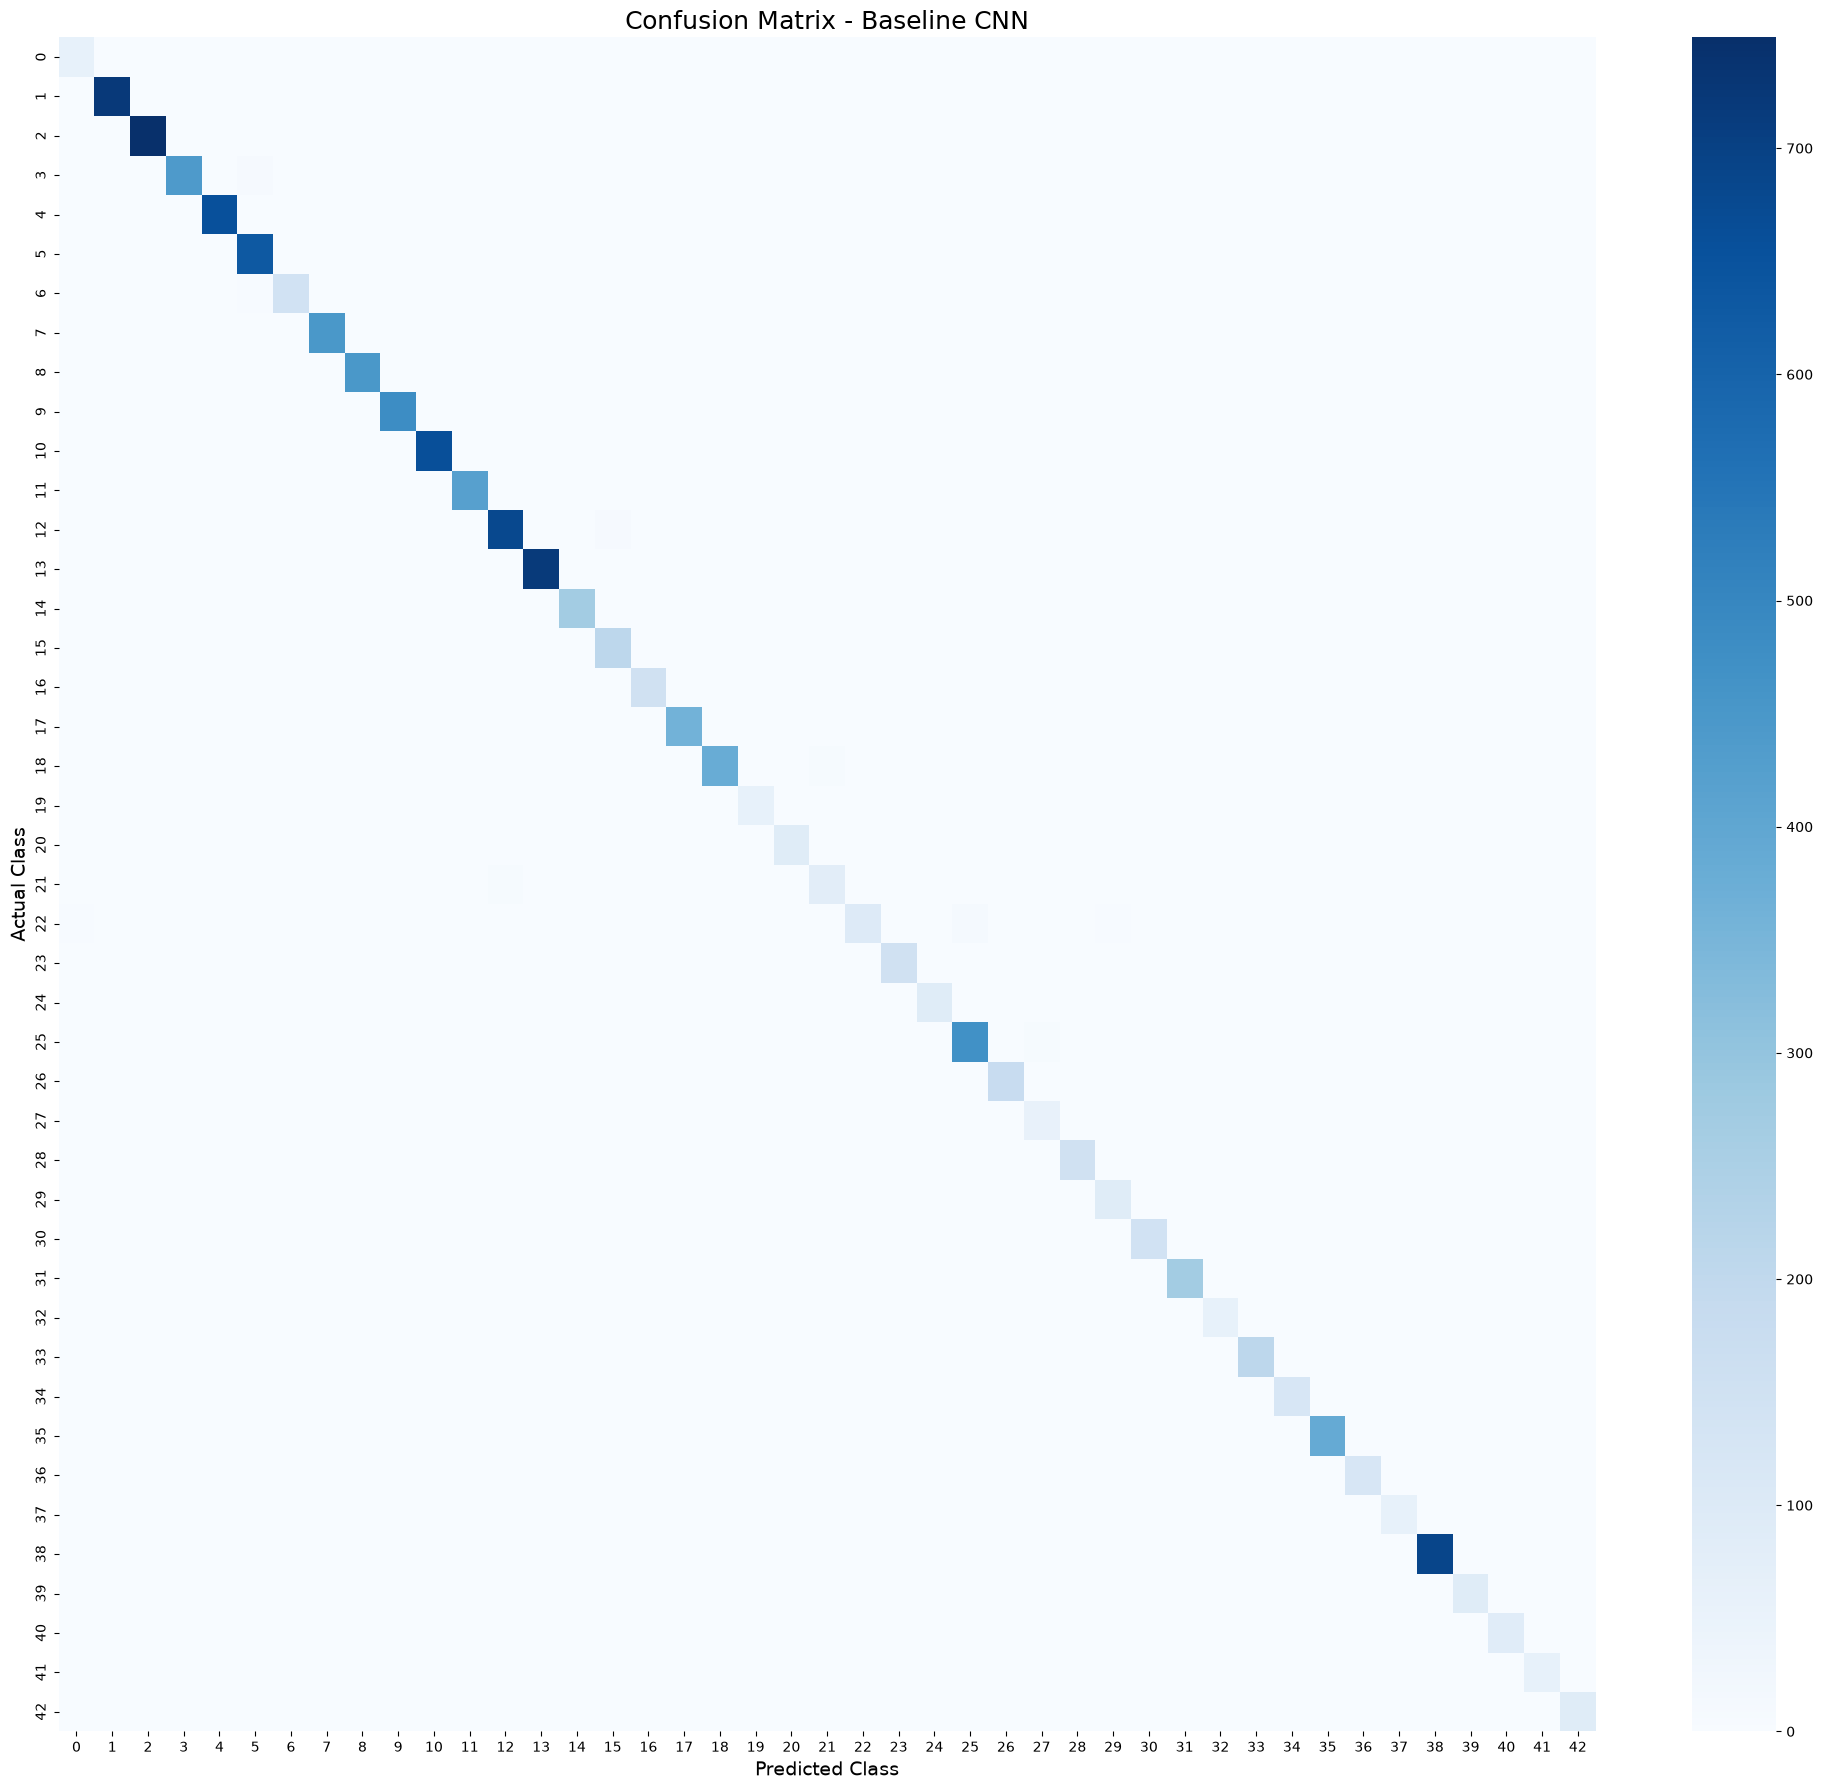

Saved: c:\Projects\Traffic_Sign_Recognition\outputs\confusion_matrices\baseline_cnn_confusion_matrix.png


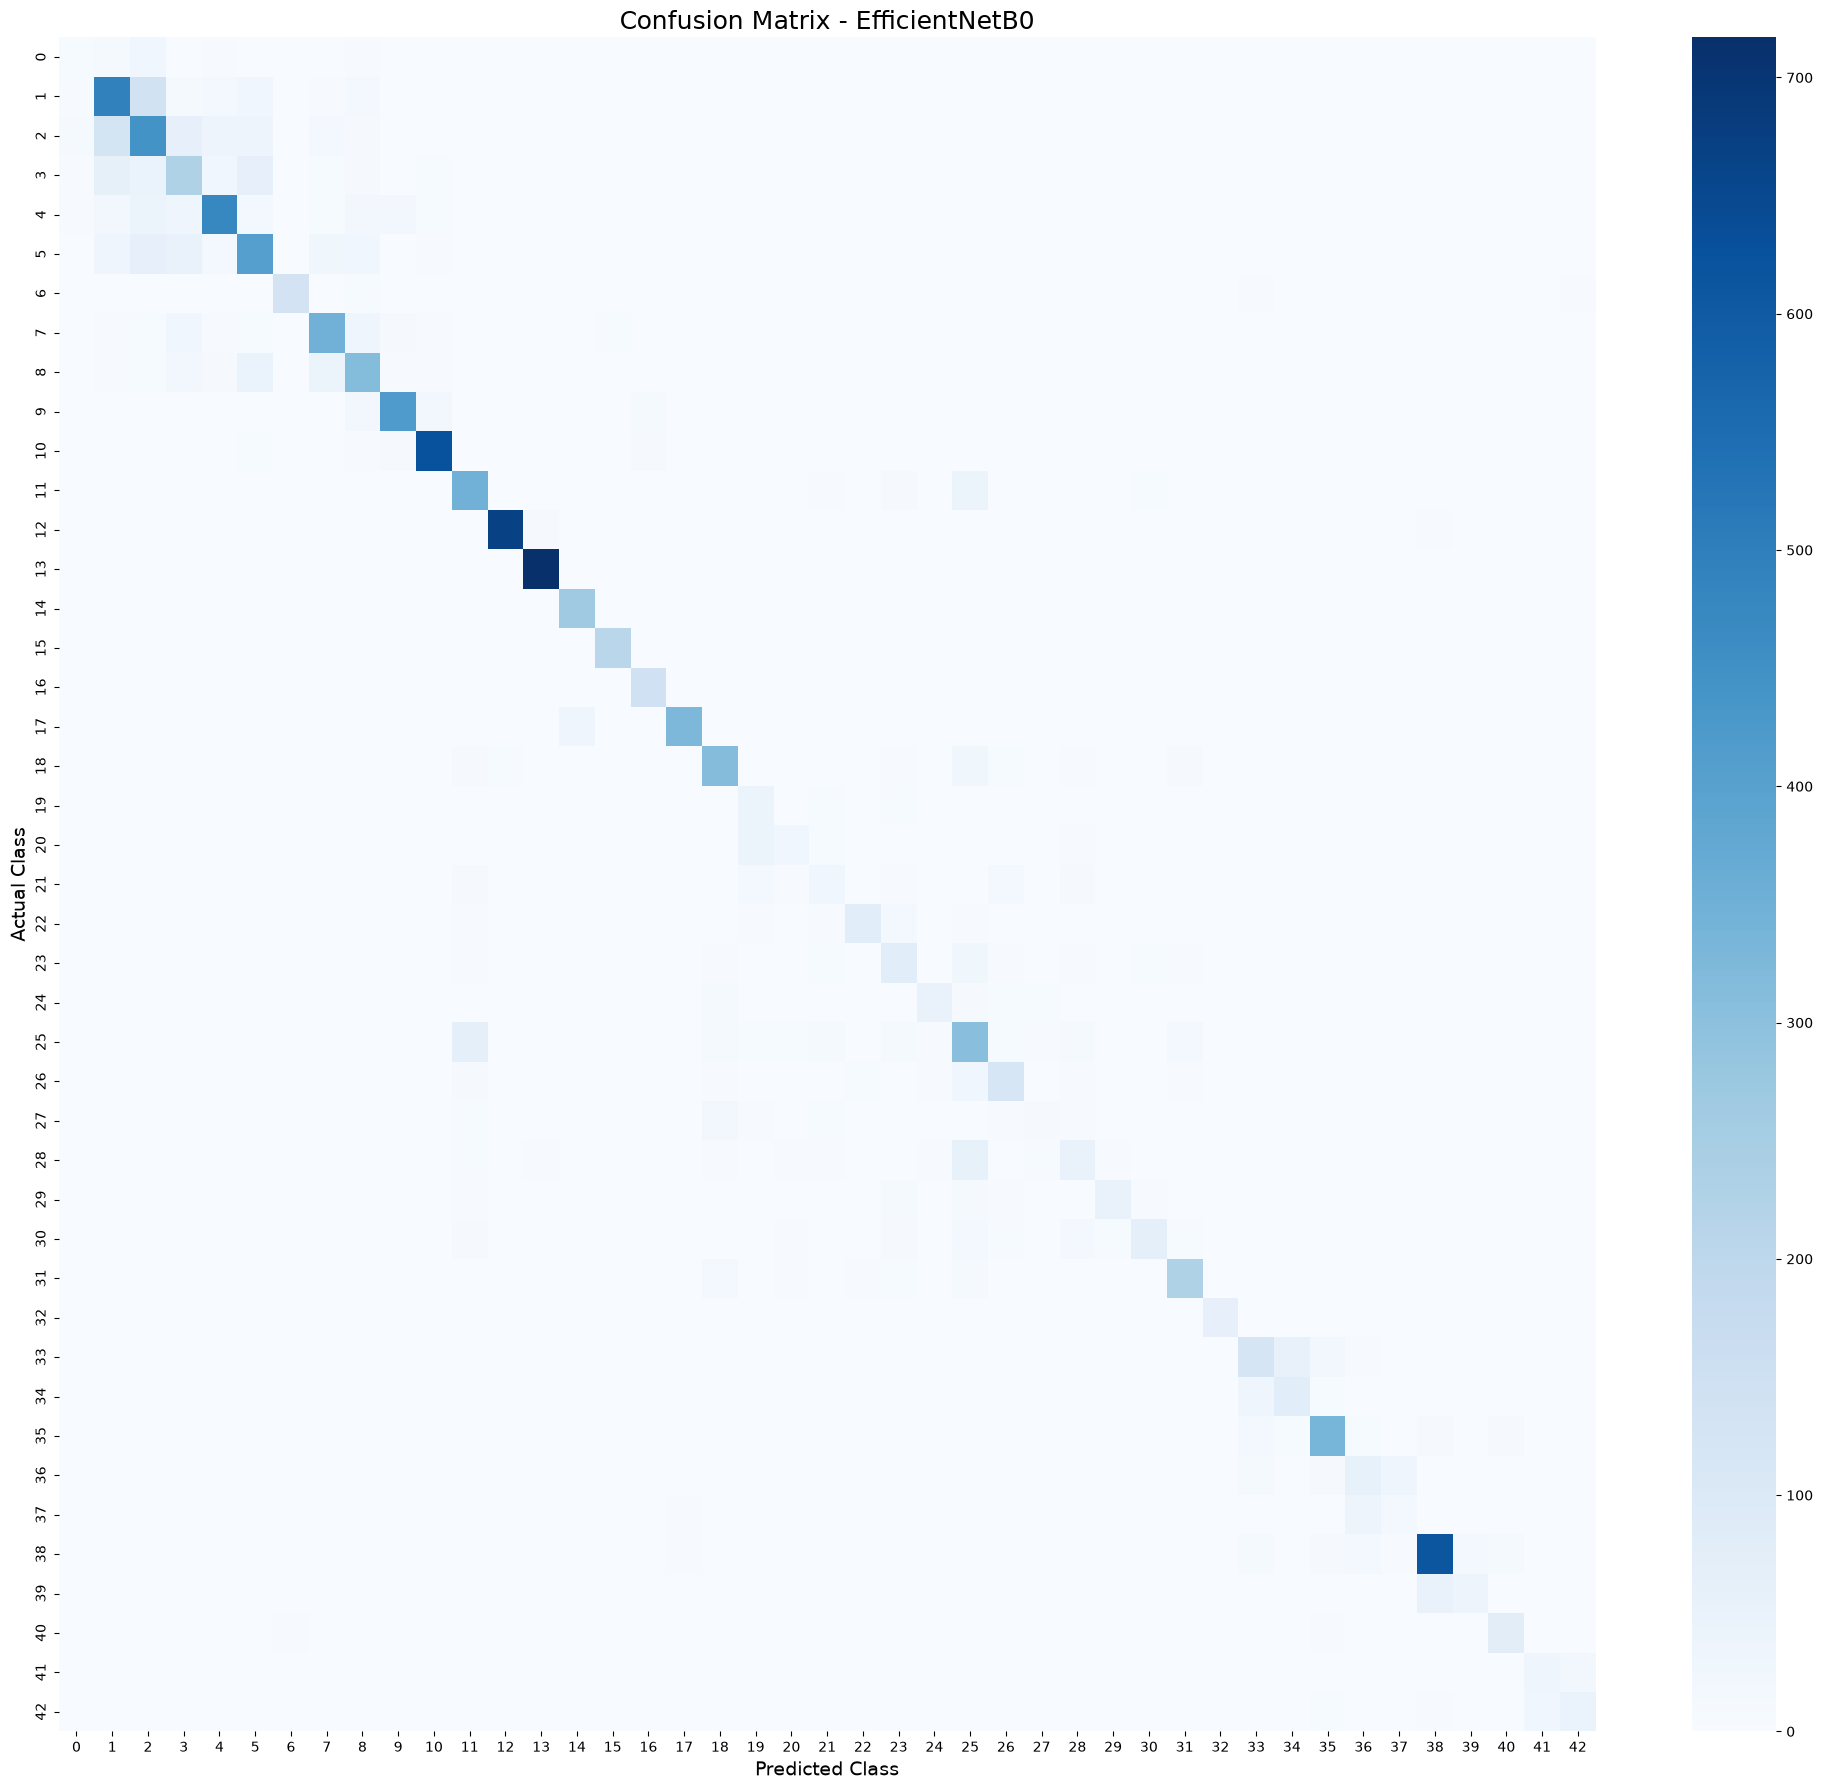

Saved: c:\Projects\Traffic_Sign_Recognition\outputs\confusion_matrices\efficientnet_b0_confusion_matrix.png


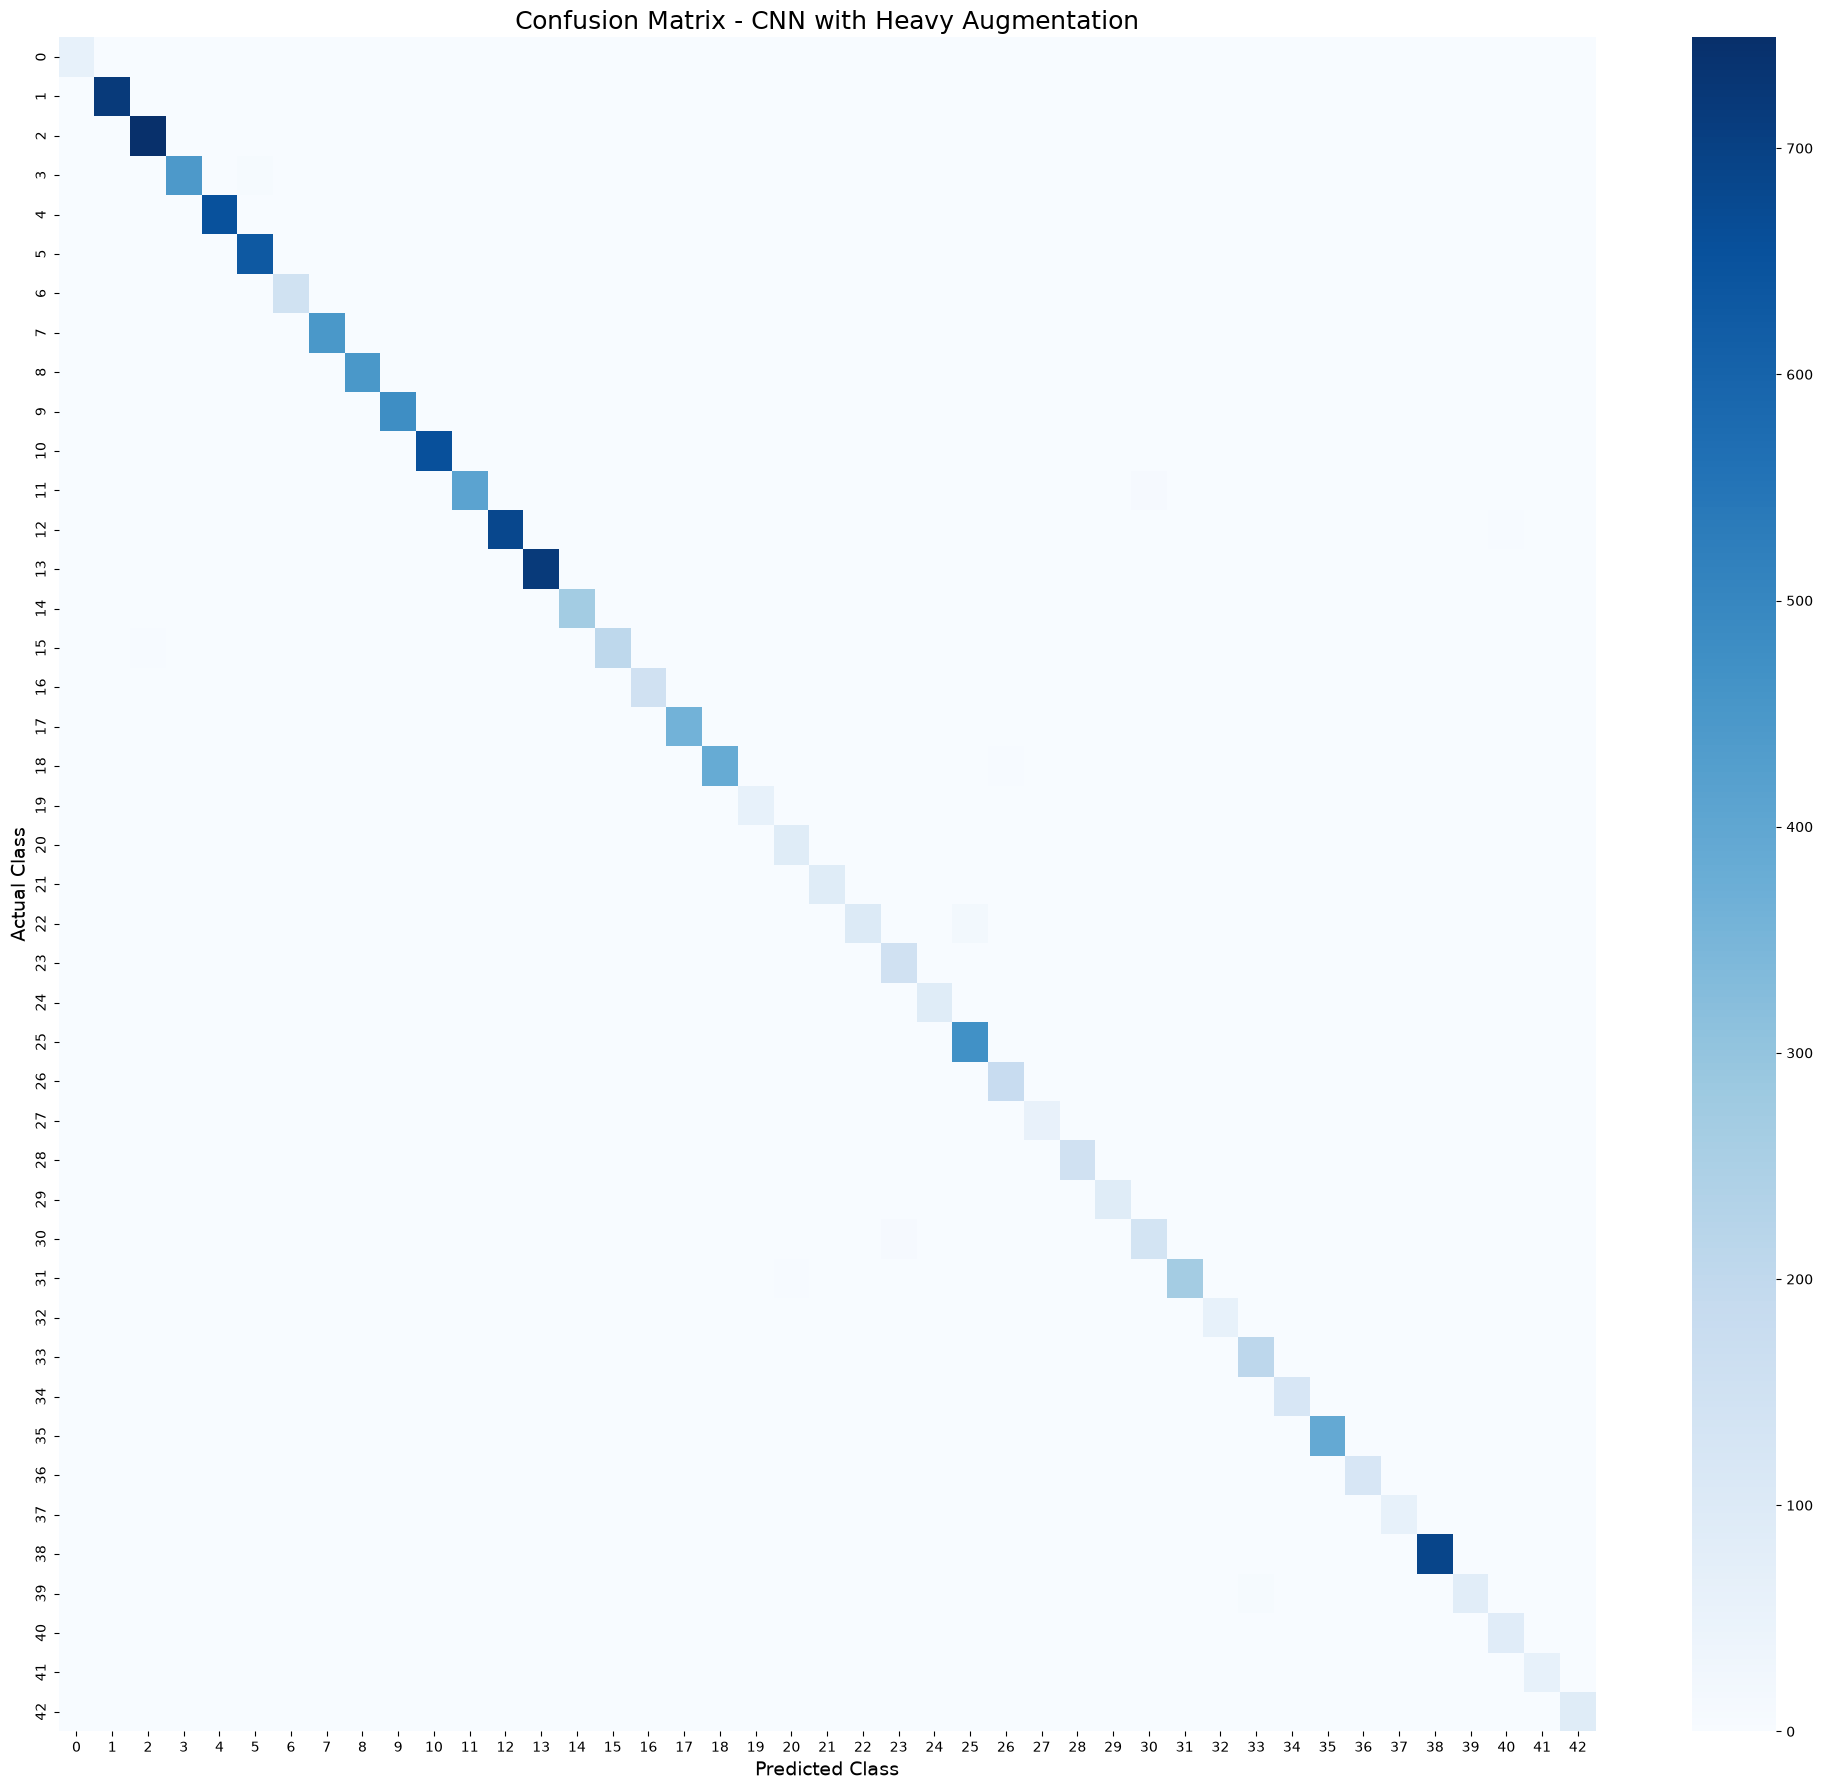

Saved: c:\Projects\Traffic_Sign_Recognition\outputs\confusion_matrices\heavy_augmentation_cnn_confusion_matrix.png


In [17]:
# Baseline CNN
plot_confusion_matrix(
    y_true,
    baseline_predictions,
    "Baseline CNN",
    "baseline_cnn_confusion_matrix.png"
)

# EfficientNetB0
plot_confusion_matrix(
    y_true,
    efficientnet_predictions,
    "EfficientNetB0",
    "efficientnet_b0_confusion_matrix.png"
)

# CNN with Heavy Augmentation
plot_confusion_matrix(
    y_true,
    heavy_aug_predictions,
    "CNN with Heavy Augmentation",
    "heavy_augmentation_cnn_confusion_matrix.png"
)

In [18]:
# Verify confusion matrix files

confusion_files = [
    "baseline_cnn_confusion_matrix.png",
    "efficientnet_b0_confusion_matrix.png",
    "heavy_augmentation_cnn_confusion_matrix.png"
]

for filename in confusion_files:

    file_path = CONFUSION_DIR / filename

    print(
        filename,
        "->",
        "Exists" if file_path.exists() else "Missing"
    )

baseline_cnn_confusion_matrix.png -> Exists
efficientnet_b0_confusion_matrix.png -> Exists
heavy_augmentation_cnn_confusion_matrix.png -> Exists


In [19]:
# Check corrupted test dataset folders

CORRUPTED_TEST_DIR = PROCESSED_DIR / "robustness_test"

corruption_conditions = [
    "gaussian_blur",
    "brightness",
    "occlusion",
    "combined"
]

for condition in corruption_conditions:

    condition_dir = CORRUPTED_TEST_DIR / condition

    print(f"\nCondition: {condition}")
    print("Folder exists:", condition_dir.exists())

    if condition_dir.exists():
        files = list(condition_dir.iterdir())
        print("Number of files:", len(files))
        print("Sample files:", [f.name for f in files[:5]])


Condition: gaussian_blur
Folder exists: True
Number of files: 12631
Sample files: ['gaussian_blur_metadata.csv', 'test_00000_class_16.png', 'test_00001_class_1.png', 'test_00002_class_38.png', 'test_00003_class_33.png']

Condition: brightness
Folder exists: True
Number of files: 12631
Sample files: ['brightness_metadata.csv', 'test_00000_class_16.png', 'test_00001_class_1.png', 'test_00002_class_38.png', 'test_00003_class_33.png']

Condition: occlusion
Folder exists: True
Number of files: 12631
Sample files: ['occlusion_metadata.csv', 'test_00000_class_16.png', 'test_00001_class_1.png', 'test_00002_class_38.png', 'test_00003_class_33.png']

Condition: combined
Folder exists: True
Number of files: 12631
Sample files: ['combined_metadata.csv', 'test_00000_class_16.png', 'test_00001_class_1.png', 'test_00002_class_38.png', 'test_00003_class_33.png']


In [20]:
# Inspect corrupted dataset metadata

for condition in corruption_conditions:

    condition_dir = CORRUPTED_TEST_DIR / condition

    csv_files = list(condition_dir.glob("*.csv"))

    print(f"\n{condition}:")

    if len(csv_files) == 0:
        print("ERROR: No metadata CSV found!")
        continue

    corrupted_df = pd.read_csv(csv_files[0])

    print("Metadata file:", csv_files[0].name)
    print("Dataset shape:", corrupted_df.shape)
    print("Columns:", corrupted_df.columns.tolist())
    print("Number of classes:", corrupted_df["ClassId"].nunique())
    print("Number of images:", len(corrupted_df))


gaussian_blur:
Metadata file: gaussian_blur_metadata.csv
Dataset shape: (12630, 9)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'ImagePath']
Number of classes: 43
Number of images: 12630

brightness:
Metadata file: brightness_metadata.csv
Dataset shape: (12630, 9)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'ImagePath']
Number of classes: 43
Number of images: 12630

occlusion:
Metadata file: occlusion_metadata.csv
Dataset shape: (12630, 9)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'ImagePath']
Number of classes: 43
Number of images: 12630

combined:
Metadata file: combined_metadata.csv
Dataset shape: (12630, 9)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'ImagePath']
Number of classes: 43
Number of images: 12630


In [21]:
# Function to create corrupted test datasets

def create_corrupted_dataset(condition):

    metadata_path = (
        CORRUPTED_TEST_DIR /
        condition /
        f"{condition}_metadata.csv"
    )

    corrupted_df = pd.read_csv(metadata_path)

    paths = corrupted_df["ImagePath"].astype(str).values
    labels = corrupted_df["ClassId"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [22]:
# Load Gaussian Blur test dataset

gaussian_blur_dataset = create_corrupted_dataset(
    "gaussian_blur"
)

# Verify one batch

for images, labels in gaussian_blur_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (64, 64, 64, 3)
Label batch shape: (64,)
Minimum pixel value: 0.019607844
Maximum pixel value: 1.0


In [23]:
# Evaluate all models on Gaussian Blur

gaussian_baseline, _, _ = evaluate_model(
    baseline_model,
    gaussian_blur_dataset,
    "Baseline CNN - Gaussian Blur"
)

gaussian_efficientnet, _, _ = evaluate_model(
    efficientnet_model,
    gaussian_blur_dataset,
    "EfficientNetB0 - Gaussian Blur"
)

gaussian_heavy_aug, _, _ = evaluate_model(
    heavy_aug_model,
    gaussian_blur_dataset,
    "Heavy Augmentation CNN - Gaussian Blur"
)

print("\nGaussian Blur evaluation completed!")

198/198 ━━━━━━━━━━━━━━━━━━━━ 16s 82ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 14s 69ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step

Gaussian Blur evaluation completed!


In [24]:
# Evaluate all models on remaining corruption conditions

corruption_results = {
    "gaussian_blur": {
        "Baseline CNN": gaussian_baseline,
        "EfficientNetB0": gaussian_efficientnet,
        "CNN with Heavy Augmentation": gaussian_heavy_aug
    }
}

remaining_conditions = [
    "brightness",
    "occlusion",
    "combined"
]

models = {
    "Baseline CNN": baseline_model,
    "EfficientNetB0": efficientnet_model,
    "CNN with Heavy Augmentation": heavy_aug_model
}

for condition in remaining_conditions:

    print(f"\n{'='*60}")
    print(f"Evaluating condition: {condition.upper()}")
    print(f"{'='*60}")

    corrupted_dataset = create_corrupted_dataset(condition)

    condition_results = {}

    for model_name, model in models.items():

        result, _, _ = evaluate_model(
            model,
            corrupted_dataset,
            f"{model_name} - {condition}"
        )

        condition_results[model_name] = result

    corruption_results[condition] = condition_results

    print(f"\n{condition.upper()} evaluation completed!")


Evaluating condition: BRIGHTNESS
198/198 ━━━━━━━━━━━━━━━━━━━━ 16s 83ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 14s 72ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step

BRIGHTNESS evaluation completed!

Evaluating condition: OCCLUSION
198/198 ━━━━━━━━━━━━━━━━━━━━ 19s 93ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 16s 79ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 13s 64ms/step

OCCLUSION evaluation completed!

Evaluating condition: COMBINED
198/198 ━━━━━━━━━━━━━━━━━━━━ 18s 90ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 15s 77ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step

COMBINED evaluation completed!


In [25]:
# Verify robustness evaluation results

for condition, results in corruption_results.items():

    print(f"\n{condition.upper()}")

    for model_name, metrics in results.items():

        print(
            model_name,
            "Accuracy:",
            round(metrics["Accuracy"], 4)
        )


GAUSSIAN_BLUR
Baseline CNN Accuracy: 0.9921
EfficientNetB0 Accuracy: 0.7433
CNN with Heavy Augmentation Accuracy: 0.9874

BRIGHTNESS
Baseline CNN Accuracy: 0.983
EfficientNetB0 Accuracy: 0.7422
CNN with Heavy Augmentation Accuracy: 0.9785

OCCLUSION
Baseline CNN Accuracy: 0.8823
EfficientNetB0 Accuracy: 0.4424
CNN with Heavy Augmentation Accuracy: 0.8729

COMBINED
Baseline CNN Accuracy: 0.8546
EfficientNetB0 Accuracy: 0.4216
CNN with Heavy Augmentation Accuracy: 0.8419


In [26]:
# Save robustness evaluation results

robustness_rows = []

for condition, results in corruption_results.items():

    for model_name, metrics in results.items():

        robustness_rows.append({
            "Condition": condition,
            "Model": model_name,
            "Accuracy": metrics["Accuracy"],
            "Macro Precision": metrics["Macro Precision"],
            "Macro Recall": metrics["Macro Recall"],
            "Macro F1-score": metrics["Macro F1-score"]
        })

robustness_df = pd.DataFrame(robustness_rows)

robustness_df.to_csv(
    ROBUSTNESS_DIR / "corruption_evaluation_results.csv",
    index=False
)

display(
    robustness_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1-score": "{:.4f}"
    })
)

print("Robustness results saved successfully!")

,Condition,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,gaussian_blur,Baseline CNN,0.9921,0.9883,0.9893,0.9884
1,gaussian_blur,EfficientNetB0,0.7433,0.6851,0.6549,0.6604
2,gaussian_blur,CNN with Heavy Augmentation,0.9874,0.9807,0.9828,0.9812
3,brightness,Baseline CNN,0.9830,0.9812,0.9692,0.9734
4,brightness,EfficientNetB0,0.7422,0.6720,0.6559,0.6568
5,brightness,CNN with Heavy Augmentation,0.9785,0.9749,0.9726,0.9727
6,occlusion,Baseline CNN,0.8823,0.8823,0.8580,0.8610
7,occlusion,EfficientNetB0,0.4424,0.4417,0.3565,0.3398
8,occlusion,CNN with Heavy Augmentation,0.8729,0.8651,0.8447,0.8475
9,combined,Baseline CNN,0.8546,0.8539,0.8248,0.8295


Robustness results saved successfully!


In [27]:
# Clean test accuracy reference

clean_accuracies = {
    "Baseline CNN": baseline_results["Accuracy"],
    "EfficientNetB0": efficientnet_results["Accuracy"],
    "CNN with Heavy Augmentation": heavy_aug_results["Accuracy"]
}

print("Clean test accuracies:")

for model_name, accuracy in clean_accuracies.items():
    print(f"{model_name}: {accuracy:.4f}")

Clean test accuracies:
Baseline CNN: 0.9918
EfficientNetB0: 0.7539
CNN with Heavy Augmentation: 0.9912


In [28]:
# Calculate accuracy drops for each corruption condition

accuracy_drop_rows = []

for condition, results in corruption_results.items():

    for model_name, metrics in results.items():

        clean_accuracy = clean_accuracies[model_name]
        corrupted_accuracy = metrics["Accuracy"]

        accuracy_drop = (
            clean_accuracy - corrupted_accuracy
        )

        accuracy_drop_percentage_points = accuracy_drop * 100

        relative_drop_percentage = (
            accuracy_drop / clean_accuracy
        ) * 100

        accuracy_drop_rows.append({
            "Condition": condition,
            "Model": model_name,
            "Clean Accuracy": clean_accuracy,
            "Corrupted Accuracy": corrupted_accuracy,
            "Accuracy Drop (percentage points)": accuracy_drop_percentage_points,
            "Relative Accuracy Drop (%)": relative_drop_percentage
        })

accuracy_drop_df = pd.DataFrame(accuracy_drop_rows)

display(
    accuracy_drop_df.style.format({
        "Clean Accuracy": "{:.4f}",
        "Corrupted Accuracy": "{:.4f}",
        "Accuracy Drop (percentage points)": "{:.2f}",
        "Relative Accuracy Drop (%)": "{:.2f}"
    })
)

,Condition,Model,Clean Accuracy,Corrupted Accuracy,Accuracy Drop (percentage points),Relative Accuracy Drop (%)
0,gaussian_blur,Baseline CNN,0.9918,0.9921,-0.02,-0.02
1,gaussian_blur,EfficientNetB0,0.7539,0.7433,1.06,1.41
2,gaussian_blur,CNN with Heavy Augmentation,0.9912,0.9874,0.38,0.38
3,brightness,Baseline CNN,0.9918,0.9830,0.89,0.89
4,brightness,EfficientNetB0,0.7539,0.7422,1.17,1.55
5,brightness,CNN with Heavy Augmentation,0.9912,0.9785,1.27,1.28
6,occlusion,Baseline CNN,0.9918,0.8823,10.95,11.04
7,occlusion,EfficientNetB0,0.7539,0.4424,31.16,41.33
8,occlusion,CNN with Heavy Augmentation,0.9912,0.8729,11.83,11.93
9,combined,Baseline CNN,0.9918,0.8546,13.73,13.84


In [29]:
# Save accuracy drop analysis

accuracy_drop_df.to_csv(
    ROBUSTNESS_DIR / "accuracy_drop_analysis.csv",
    index=False
)

print("Accuracy drop analysis saved successfully!")

Accuracy drop analysis saved successfully!


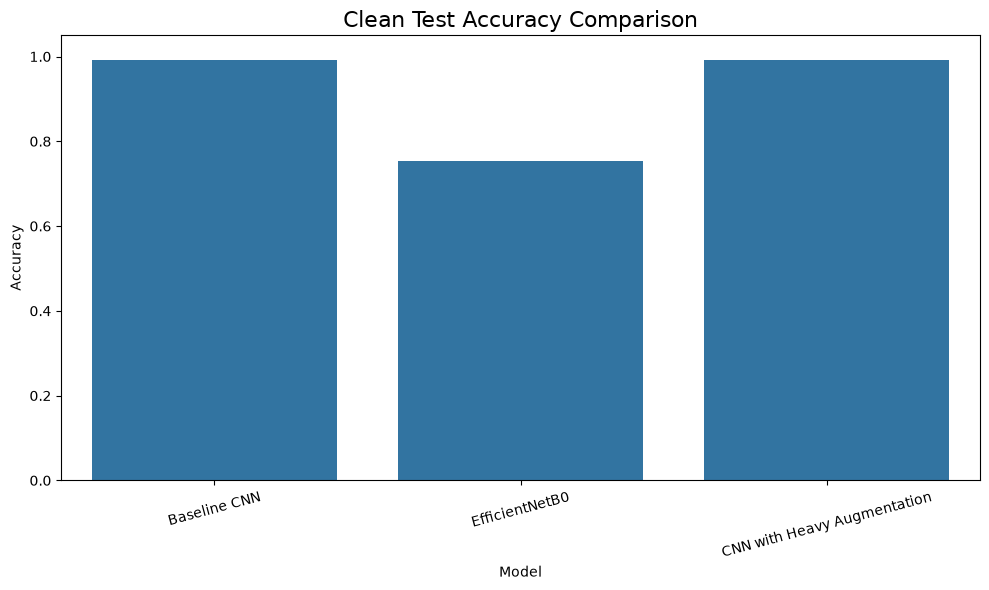

In [30]:
# Chart 1: Clean test accuracy comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=clean_results_df.reset_index(),
    x="Model",
    y="Accuracy"
)

plt.title("Clean Test Accuracy Comparison", fontsize=16)
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    ROBUSTNESS_DIR / "clean_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

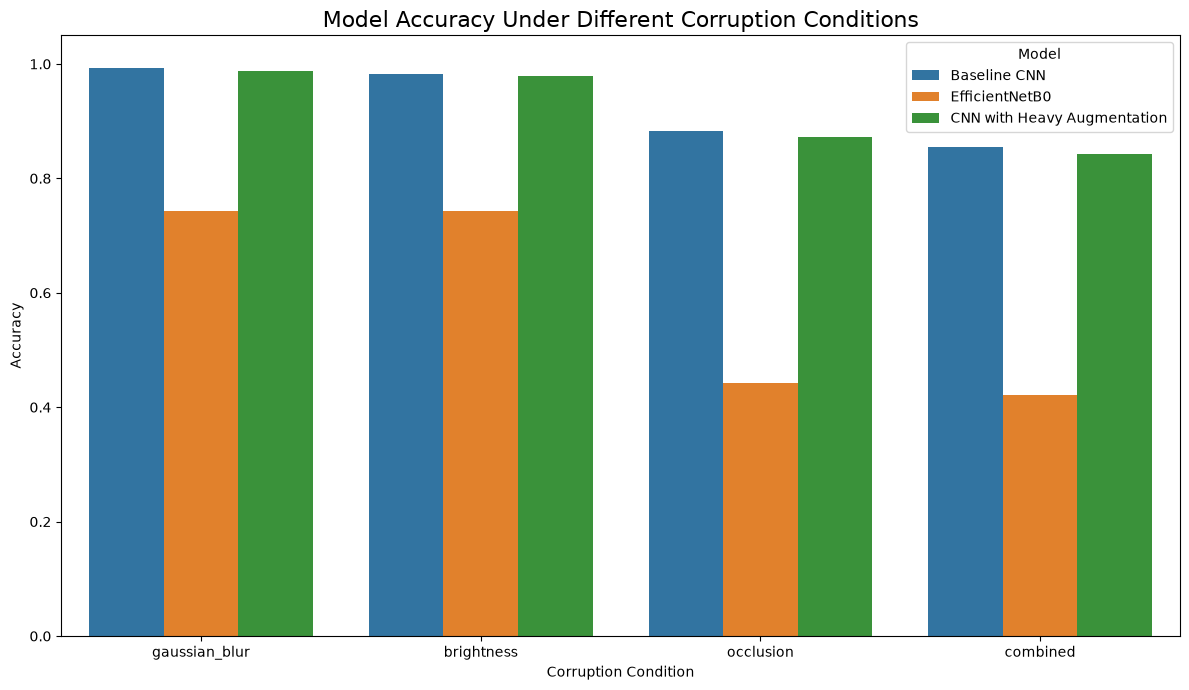

In [31]:
# Chart 2: Accuracy under different corruption conditions

plt.figure(figsize=(12, 7))

sns.barplot(
    data=robustness_df,
    x="Condition",
    y="Accuracy",
    hue="Model"
)

plt.title(
    "Model Accuracy Under Different Corruption Conditions",
    fontsize=16
)

plt.xlabel("Corruption Condition")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)

plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    ROBUSTNESS_DIR / "corruption_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

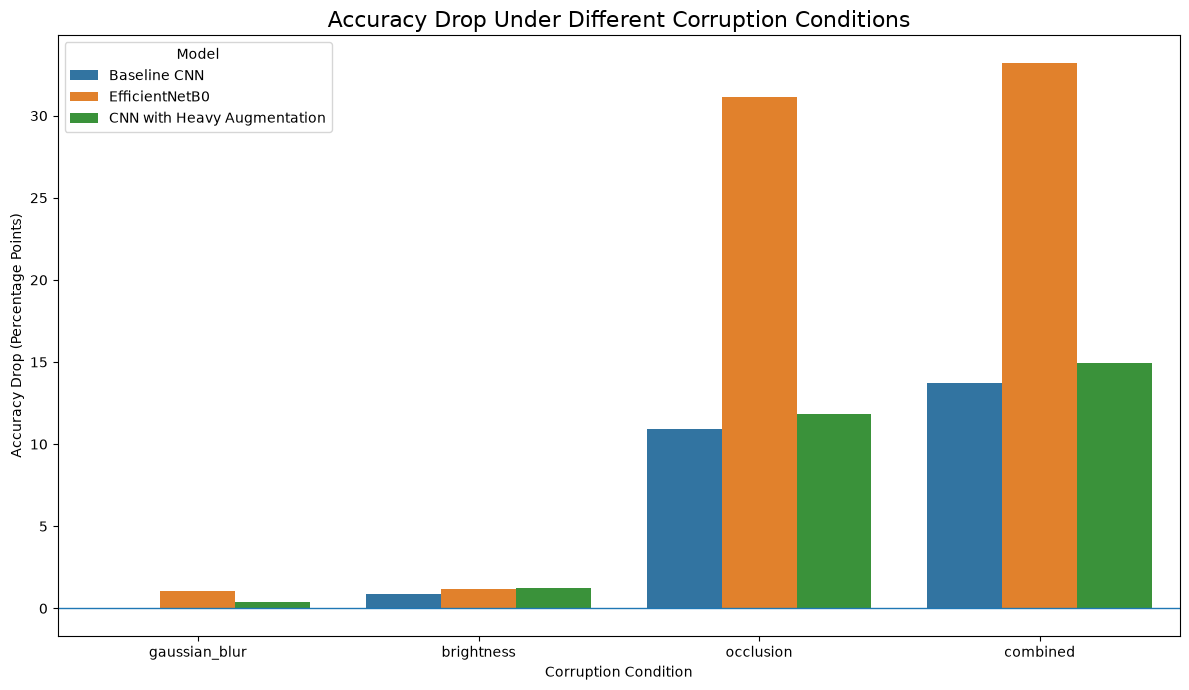

In [32]:
# Chart 3: Accuracy drop under corruption conditions

plt.figure(figsize=(12, 7))

sns.barplot(
    data=accuracy_drop_df,
    x="Condition",
    y="Accuracy Drop (percentage points)",
    hue="Model"
)

plt.title(
    "Accuracy Drop Under Different Corruption Conditions",
    fontsize=16
)

plt.xlabel("Corruption Condition")
plt.ylabel("Accuracy Drop (Percentage Points)")

plt.axhline(0, linewidth=1)
plt.legend(title="Model")

plt.tight_layout()

plt.savefig(
    ROBUSTNESS_DIR / "accuracy_drop_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [33]:
# Verify comparison charts

chart_files = [
    "clean_accuracy_comparison.png",
    "corruption_accuracy_comparison.png",
    "accuracy_drop_comparison.png"
]

for filename in chart_files:

    file_path = ROBUSTNESS_DIR / filename

    print(
        filename,
        "->",
        "Exists" if file_path.exists() else "Missing"
    )

clean_accuracy_comparison.png -> Exists
corruption_accuracy_comparison.png -> Exists
accuracy_drop_comparison.png -> Exists


In [34]:
# Create consolidated accuracy comparison

comparison_rows = []

for model_name in clean_accuracies:

    row = {
        "Model": model_name,
        "Clean": clean_accuracies[model_name]
    }

    for condition in corruption_conditions:

        row[condition] = corruption_results[condition][model_name]["Accuracy"]

    comparison_rows.append(row)

final_accuracy_comparison = pd.DataFrame(comparison_rows)

display(
    final_accuracy_comparison.set_index("Model").style.format("{:.4f}")
)

,Clean,gaussian_blur,brightness,occlusion,combined
Model,,,,,
Baseline CNN,0.9918,0.9921,0.9830,0.8823,0.8546
EfficientNetB0,0.7539,0.7433,0.7422,0.4424,0.4216
CNN with Heavy Augmentation,0.9912,0.9874,0.9785,0.8729,0.8419


In [35]:
# Calculate average accuracy across corruption conditions

corruption_columns = [
    "gaussian_blur",
    "brightness",
    "occlusion",
    "combined"
]

final_accuracy_comparison["Average Corrupted Accuracy"] = (
    final_accuracy_comparison[corruption_columns].mean(axis=1)
)

final_accuracy_comparison["Overall Average Accuracy"] = (
    final_accuracy_comparison[
        ["Clean"] + corruption_columns
    ].mean(axis=1)
)

display(
    final_accuracy_comparison.set_index("Model").style.format("{:.4f}")
)

,Clean,gaussian_blur,brightness,occlusion,combined,Average Corrupted Accuracy,Overall Average Accuracy
Model,,,,,,,
Baseline CNN,0.9918,0.9921,0.9830,0.8823,0.8546,0.9280,0.9408
EfficientNetB0,0.7539,0.7433,0.7422,0.4424,0.4216,0.5874,0.6207
CNN with Heavy Augmentation,0.9912,0.9874,0.9785,0.8729,0.8419,0.9202,0.9344


In [36]:
# Save consolidated comparison

final_accuracy_comparison.to_csv(
    ROBUSTNESS_DIR / "final_model_performance_comparison.csv",
    index=False
)

print("Final model performance comparison saved successfully!")

Final model performance comparison saved successfully!


In [37]:
# Identify best model based on average corrupted accuracy

best_model_row = final_accuracy_comparison.loc[
    final_accuracy_comparison["Average Corrupted Accuracy"].idxmax()
]

print("Best model based on average corrupted accuracy:")
print("Model:", best_model_row["Model"])

print(
    "Average corrupted accuracy:",
    round(best_model_row["Average Corrupted Accuracy"], 4)
)

print(
    "Overall average accuracy:",
    round(best_model_row["Overall Average Accuracy"], 4)
)

Best model based on average corrupted accuracy:
Model: Baseline CNN
Average corrupted accuracy: 0.928
Overall average accuracy: 0.9408
